<a href="https://colab.research.google.com/github/eyupyahyasuzen73841/Lab3-Architectures-and-Costs/blob/main/ML_Lab3_Architectures_and_Costs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q torchinfo thop

In [ ]:
import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Normalize and transform images
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

# Download Fashion-MNIST
full_train = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Split into 55,000 training and 5,000 validation images
train_dataset, val_dataset = random_split(
    full_train,
    [55000, 5000],
    generator=torch.Generator().manual_seed(42)
)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.9MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 203kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.76MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 3.51MB/s]

Training images: 55000
Validation images: 5000
Test images: 10000


In [ ]:
import torch
import torch.nn as nn

# MLP Model
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)

# Create MLP model
mlp_model = MLP()

# Count parameters
mlp_params = sum(p.numel() for p in mlp_model.parameters())

print("MLP Model Created Successfully!")
print("MLP Parameters:", mlp_params)

MLP Model Created Successfully!
MLP Parameters: 235146


In [ ]:
# CNN Model
class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 10)
        )

    def forward(self, x):
        return self.network(x)

# Create CNN model
cnn_model = CNN()

# Count parameters
cnn_params = sum(p.numel() for p in cnn_model.parameters())

print("CNN Model Created Successfully!")
print("CNN Parameters:", cnn_params)

CNN Model Created Successfully!
CNN Parameters: 20490


In [ ]:
# Attention Model
class AttentionModel(nn.Module):
    def __init__(self):
        super().__init__()

        # Convert 7x7 patches into 64-dimensional vectors
        self.patch_embedding = nn.Linear(49, 64)

        # Transformer Encoder Layer
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=64,
            nhead=4,
            dim_feedforward=128,
            batch_first=True
        )

        # Two Transformer Encoder Layers
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        # Classification Layer
        self.fc = nn.Linear(64, 10)

    def forward(self, x):
        batch_size = x.size(0)

        # Split 28x28 images into 16 patches of 7x7
        x = x.unfold(2, 7, 7).unfold(3, 7, 7)
        x = x.contiguous().view(batch_size, 16, 49)

        # Patch embedding
        x = self.patch_embedding(x)

        # Transformer
        x = self.transformer(x)

        # Mean pooling
        x = x.mean(dim=1)

        return self.fc(x)


# Create Attention model
attention_model = AttentionModel()

# Count parameters
attention_params = sum(
    p.numel() for p in attention_model.parameters()
)

print("Attention Model Created Successfully!")
print("Attention Parameters:", attention_params)

Attention Model Created Successfully!
Attention Parameters: 70794


In [ ]:
from torchinfo import summary

print("========== MLP MODEL ==========")
summary(mlp_model, input_size=(1, 1, 28, 28))

print("\n========== CNN MODEL ==========")
summary(cnn_model, input_size=(1, 1, 28, 28))

print("\n========== ATTENTION MODEL ==========")
summary(attention_model, input_size=(1, 1, 28, 28))

========== MLP MODEL ==========

========== CNN MODEL ==========

========== ATTENTION MODEL ==========


Layer (type:depth-idx)                        Output Shape              Param #
AttentionModel                                [1, 10]                   --
├─Linear: 1-1                                 [1, 16, 64]               3,200
├─TransformerEncoder: 1-2                     [1, 16, 64]               --
│    └─ModuleList: 2-1                        --                        --
│    │    └─TransformerEncoderLayer: 3-1      [1, 16, 64]               33,472
│    │    └─TransformerEncoderLayer: 3-2      [1, 16, 64]               33,472
├─Linear: 1-3                                 [1, 10]                   650
Total params: 70,794
Trainable params: 70,794
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.04
Input size (MB): 0.00
Forward/backward pass size (MB): 0.09
Params size (MB): 0.15
Estimated Total Size (MB): 0.24

In [ ]:
# TASK 3 - Manual FLOPs Calculations

# 1. MLP - First Linear Layer (784 -> 256)
mlp_flops = 2 * 784 * 256

# 2. CNN - First Convolutional Layer
cnn_flops = 2 * 3 * 3 * 1 * 16 * 28 * 28

# 3. Attention - QKV Projections
attention_qkv_flops = 2 * 16 * 64 * 3 * 64

# 4. Attention - Attention Scores
attention_scores_flops = 2 * 16 * 16 * 64

print("TASK 3 - MANUAL FLOPs CALCULATIONS")
print("----------------------------------")

print("MLP First Linear Layer:", mlp_flops, "FLOPs")
print("CNN First Conv Layer:", cnn_flops, "FLOPs")
print("Attention QKV Projections:", attention_qkv_flops, "FLOPs")
print("Attention Scores:", attention_scores_flops, "FLOPs")

TASK 3 - MANUAL FLOPs CALCULATIONS
----------------------------------
MLP First Linear Layer: 401408 FLOPs
CNN First Conv Layer: 225792 FLOPs
Attention QKV Projections: 393216 FLOPs
Attention Scores: 32768 FLOPs


In [ ]:
from thop import profile
import torch

# Use the same device for models and input
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

mlp_model = mlp_model.to(device)
cnn_model = cnn_model.to(device)
attention_model = attention_model.to(device)

dummy_input = torch.randn(1, 1, 28, 28).to(device)

# MLP
mlp_macs, mlp_params_thop = profile(
    mlp_model, inputs=(dummy_input,), verbose=False
)

# CNN
cnn_macs, cnn_params_thop = profile(
    cnn_model, inputs=(dummy_input,), verbose=False
)

# Attention
attention_macs, attention_params_thop = profile(
    attention_model, inputs=(dummy_input,), verbose=False
)

print("TASK 3 - THOP PROFILING")
print("-----------------------")

print(f"MLP: {mlp_macs:,.0f} MACs")
print(f"CNN: {cnn_macs:,.0f} MACs")
print(f"Attention: {attention_macs:,.0f} MACs")

print("\nApproximate FLOPs (2 per MAC):")
print(f"MLP: {2 * mlp_macs:,.0f}")
print(f"CNN: {2 * cnn_macs:,.0f}")
print(f"Attention: {2 * attention_macs:,.0f}")

TASK 3 - THOP PROFILING
-----------------------
MLP: 469,504 MACs
CNN: 1,031,744 MACs
Attention: 591,488 MACs

Approximate FLOPs (2 per MAC):
MLP: 939,008
CNN: 2,063,488
Attention: 1,182,976


In [ ]:
import torch
import time
import numpy as np

# Recreate clean models after THOP profiling
mlp_model = MLP().to(device)
cnn_model = CNN().to(device)
attention_model = AttentionModel().to(device)

def measure_latency(model, batch_size, runs):
    model.eval()
    device = next(model.parameters()).device
    x = torch.randn(batch_size, 1, 28, 28, device=device)

    def synchronize():
        if device.type == "cuda":
            torch.cuda.synchronize()

    # Warm-up
    with torch.inference_mode():
        for _ in range(10):
            model(x)

        synchronize()
        times = []

        for _ in range(runs):
            synchronize()
            start = time.perf_counter()

            model(x)

            synchronize()
            end = time.perf_counter()

            times.append((end - start) * 1000)

    return np.median(times)


models = {
    "MLP": mlp_model,
    "CNN": cnn_model,
    "Attention": attention_model
}

latency_results = {}

print("TASK 3 - INFERENCE LATENCY")
print("--------------------------")

for name, model in models.items():
    latency_1 = measure_latency(model, 1, 100)
    latency_128 = measure_latency(model, 128, 20)

    latency_results[name] = {
        "batch_1": latency_1,
        "batch_128": latency_128
    }

    print(f"\n{name}")
    print(f"Batch 1 Median: {latency_1:.4f} ms")
    print(f"Batch 128 Median: {latency_128:.4f} ms")

print("\nTASK 3 - LATENCY COMPLETED!")

TASK 3 - INFERENCE LATENCY
--------------------------

MLP
Batch 1 Median: 0.1373 ms
Batch 128 Median: 0.2003 ms

CNN
Batch 1 Median: 0.2897 ms
Batch 128 Median: 0.6950 ms

Attention
Batch 1 Median: 0.7769 ms
Batch 128 Median: 1.3043 ms

TASK 3 - LATENCY COMPLETED!


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Clean models
mlp_model = MLP().to(device)
cnn_model = CNN().to(device)
attention_model = AttentionModel().to(device)

models = {
    "MLP": mlp_model,
    "CNN": cnn_model,
    "Attention": attention_model
}

criterion = nn.CrossEntropyLoss()

def train_model(model, name):
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    for epoch in range(5):
        model.train()
        total_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"{name} - Epoch {epoch+1}/5 - "
            f"Loss: {total_loss/len(train_loader):.4f}"
        )

    # Test accuracy
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100 * correct / total

    print(f"{name} Test Accuracy: {accuracy:.2f}%")
    print("-----------------------------")

    return accuracy


accuracy_results = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    accuracy_results[name] = train_model(model, name)

print("\nTASK 4 COMPLETED!")


Training MLP...
MLP - Epoch 1/5 - Loss: 0.4929
MLP - Epoch 2/5 - Loss: 0.3524
MLP - Epoch 3/5 - Loss: 0.3119
MLP - Epoch 4/5 - Loss: 0.2870
MLP - Epoch 5/5 - Loss: 0.2658
MLP Test Accuracy: 87.68%
-----------------------------

Training CNN...
CNN - Epoch 1/5 - Loss: 0.5167
CNN - Epoch 2/5 - Loss: 0.3359
CNN - Epoch 3/5 - Loss: 0.2979
CNN - Epoch 4/5 - Loss: 0.2762
CNN - Epoch 5/5 - Loss: 0.2566
CNN Test Accuracy: 89.46%
-----------------------------

Training Attention...
Attention - Epoch 1/5 - Loss: 0.8461
Attention - Epoch 2/5 - Loss: 0.5453
Attention - Epoch 3/5 - Loss: 0.4776
Attention - Epoch 4/5 - Loss: 0.4453
Attention - Epoch 5/5 - Loss: 0.4236
Attention Test Accuracy: 84.40%
-----------------------------

TASK 4 COMPLETED!


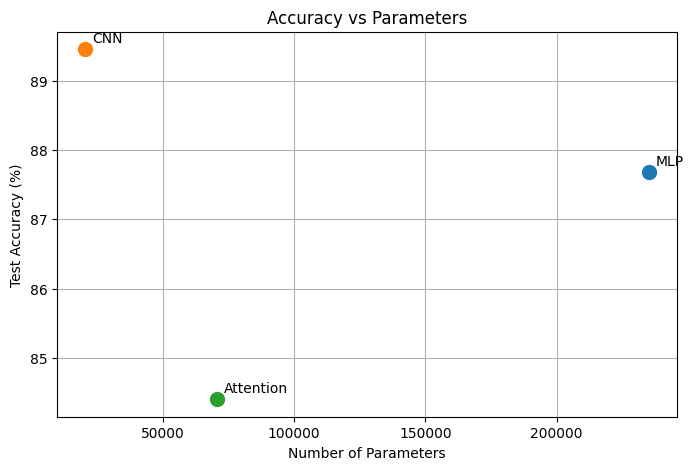

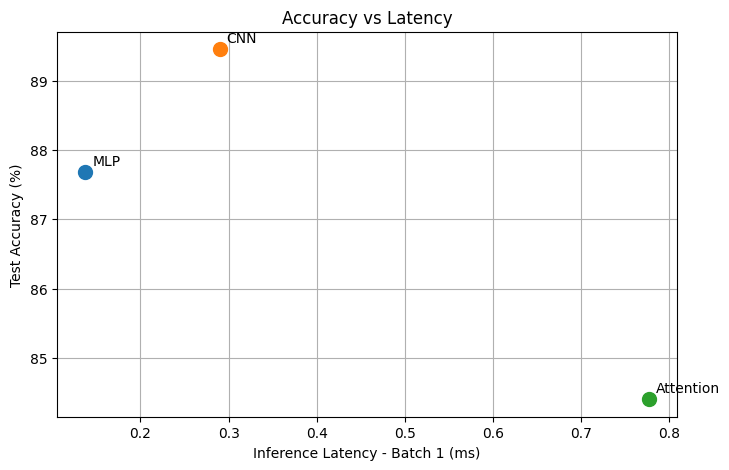

TASK 5 - PLOTS COMPLETED!


In [ ]:
import matplotlib.pyplot as plt

model_names = ["MLP", "CNN", "Attention"]

parameters = [
    sum(p.numel() for p in models[name].parameters())
    for name in model_names
]

accuracies = [accuracy_results[name] for name in model_names]

latencies = [
    latency_results[name]["batch_1"]
    for name in model_names
]

# Graph 1: Accuracy vs Parameters
plt.figure(figsize=(8, 5))

for i, name in enumerate(model_names):
    plt.scatter(parameters[i], accuracies[i], s=100)
    plt.annotate(name, (parameters[i], accuracies[i]),
                 xytext=(5, 5), textcoords="offset points")

plt.xlabel("Number of Parameters")
plt.ylabel("Test Accuracy (%)")
plt.title("Accuracy vs Parameters")
plt.grid(True)
plt.show()

# Graph 2: Accuracy vs Latency
plt.figure(figsize=(8, 5))

for i, name in enumerate(model_names):
    plt.scatter(latencies[i], accuracies[i], s=100)
    plt.annotate(name, (latencies[i], accuracies[i]),
                 xytext=(5, 5), textcoords="offset points")

plt.xlabel("Inference Latency - Batch 1 (ms)")
plt.ylabel("Test Accuracy (%)")
plt.title("Accuracy vs Latency")
plt.grid(True)
plt.show()

print("TASK 5 - PLOTS COMPLETED!")

In [ ]:
# TASK 6 - Generate report.md

model_names = ["MLP", "CNN", "Attention"]

report = """# Lab 3: Architectures and Their Costs

## 1. Objective
The objective of this lab is to compare MLP, CNN, and
Attention architectures using Fashion-MNIST.

## 2. Dataset
- Dataset: Fashion-MNIST
- Training samples: 55,000
- Validation samples: 5,000
- Test samples: 10,000
- Batch size: 128
- Normalization: mean=0.2860, std=0.3530

## 3. Model Comparison

| Model | Parameters | Test Accuracy (%) | Batch 1 Latency (ms) | Batch 128 Latency (ms) |
|---|---:|---:|---:|---:|
"""

for name in model_names:
    params = sum(p.numel() for p in models[name].parameters())
    accuracy = accuracy_results[name]
    lat1 = latency_results[name]["batch_1"]
    lat128 = latency_results[name]["batch_128"]

    report += (
        f"| {name} | {params:,} | {accuracy:.2f} | "
        f"{lat1:.4f} | {lat128:.4f} |\n"
    )

report += """
## 4. Computational Cost

Representative manual FLOPs calculations:

- MLP first Linear layer:
  2 * 784 * 256 = 401,408 FLOPs
- CNN first convolution:
  2 * 3 * 3 * 1 * 16 * 28 * 28 = 225,792 FLOPs
- Attention QKV projections:
  2 * 16 * 64 * 3 * 64 = 393,216 FLOPs
- Attention score calculation:
  2 * 16 * 16 * 64 = 32,768 FLOPs

THOP profiling results:

| Model | MACs | Approximate FLOPs |
|---|---:|---:|
"""

thop_results = {
    "MLP": mlp_macs,
    "CNN": cnn_macs,
    "Attention": attention_macs
}

for name in model_names:
    macs = thop_results[name]
    report += f"| {name} | {macs:,.0f} | {2 * macs:,.0f} |\n"

report += """
## 5. Architecture Trade-offs

- **MLP**: Uses fully connected layers and processes the image as a flattened vector. It is straightforward to implement, but does not explicitly exploit spatial locality and has a very high parameter footprint.
- **CNN**: Uses local convolutional filters with weight sharing to capture spatial patterns. It achieves higher accuracy with significantly fewer parameters, though it requires more MACs/FLOPs.
- **Attention**: Captures global context across image patches. While powerful and flexible, it introduces quadratic complexity relative to sequence length (patches) and requires more inference latency.
"""

with open("report.md", "w") as f:
    f.write(report)

print("report.md generated successfully!")

report.md generated successfully!
